In [ ]:
import yfinance as yf
import pandas as pd
import ta
from datetime import datetime, timedelta

# Example Nifty 50 tickers
nifty50 = [
    "RELIANCE.NS","TCS.NS","HDFCBANK.NS","INFY.NS","HINDUNILVR.NS",
    "ICICIBANK.NS","KOTAKBANK.NS","SBIN.NS","BAJFINANCE.NS","BHARTIARTL.NS",
    "AXISBANK.NS","LT.NS","MARUTI.NS","HCLTECH.NS","ITC.NS",
    "TITAN.NS","ULTRACEMCO.NS","TECHM.NS","ONGC.NS","JSWSTEEL.NS",
    "SUNPHARMA.NS","POWERGRID.NS","NTPC.NS","GRASIM.NS","WIPRO.NS",
    "BPCL.NS","DIVISLAB.NS","HINDALCO.NS","EICHERMOT.NS","DRREDDY.NS",
    "ADANIPORTS.NS","COALINDIA.NS","INDUSINDBK.NS","TATAMOTORS.NS","CIPLA.NS",
    "BRITANNIA.NS","SBILIFE.NS","HDFCLIFE.NS","VEDL.NS","SHREECEM.NS",
    "HEROMOTOCO.NS","ICICIPRULI.NS","M&M.NS","BHARATFORG.NS","HDFCAMC.NS",
    "APOLLOHOSP.NS","NTPC.NS","BAJAJFINSV.NS","ASIANPAINT.NS","COLPAL.NS","CUMMINSIND.NS"
]


end_date = datetime.today()
start_date = end_date - timedelta(days=365)

results = []

for ticker in nifty50:
    try:
        df = yf.download(ticker, start=start_date, end=end_date, progress=False)
        if df.empty:
            print(f"No data for {ticker}")
            continue

        # Ensure 1D series
        close = df['Close'].squeeze().astype(float)
        volume = df['Volume'].squeeze().astype(float)

        # Calculate indicators
        rsi_val = ta.momentum.RSIIndicator(close, window=14).rsi().iloc[-1]
        macd = ta.trend.MACD(close)
        macd_val = macd.macd().iloc[-1]
        macd_signal = macd.macd_signal().iloc[-1]
        bb = ta.volatility.BollingerBands(close, window=20, window_dev=2)
        bb_high = bb.bollinger_hband().iloc[-1]
        bb_low = bb.bollinger_lband().iloc[-1]

        # Latest values
        latest_close = close.iloc[-1]
        latest_volume = volume.iloc[-1]
        avg_volume = volume.rolling(window=20).mean().iloc[-1]

        # Momentum scoring: all 3 indicators must align
        score = 0
        if rsi_val > 50: score += 1
        if macd_val > macd_signal: score += 1
        if latest_close > bb_high: score += 1
        if latest_volume > avg_volume: score += 1

        recommendation = 'BUY' if score >= 3 else 'HOLD'

        results.append({
            'Stock': ticker,
            'Close': round(latest_close,2),
            'RSI': round(rsi_val,2),
            'MACD': round(macd_val,2),
            'MACD_Signal': round(macd_signal,2),
            'BB_High': round(bb_high,2),
            'BB_Low': round(bb_low,2),
            'Volume': round(latest_volume),
            'Avg_Volume': round(avg_volume),
            'Score': score,
            'Recommendation': recommendation
        })

    except Exception as e:
        print(f"Error processing {ticker}: {e}")

# Display results
if results:
    momentum_df = pd.DataFrame(results)
    momentum_df = momentum_df.sort_values(by='Score', ascending=False).reset_index(drop=True)
    print("Top Momentum Stocks:")
    print(momentum_df.head(5))
else:
    print("No stock data could be processed. Check tickers and network connection.")


/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py

No data for JSWSTEEL.NS


/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py

No data for TATAMOTORS.NS


/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py

No data for HEROMOTOCO.NS


/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/4000739436.py

Top Momentum Stocks:
           Stock   Close    RSI   MACD  MACD_Signal  BB_High   BB_Low  \
0  HINDUNILVR.NS  2240.8  60.24 -12.67       -33.74  2206.02  2021.91   
1     HDFCAMC.NS  2792.4  65.32  42.23       -10.92  2739.76  2152.35   
2      COLPAL.NS  2106.0  64.45 -16.17       -47.93  2034.71  1765.41   
3  ADANIPORTS.NS  1573.4  67.32  25.63         0.05  1555.92  1261.11   
4        NTPC.NS   393.6  64.02   4.30         2.17   395.07   359.43   

     Volume  Avg_Volume  Score Recommendation  
0   4882697     2343538      4            BUY  
1   2259343     1625048      4            BUY  
2   2100901      496775      4            BUY  
3   6024587     3620315      4            BUY  
4  15320653    13958030      3            BUY  


In [2]:
#!pip install --upgrade setuptools


In [3]:
import yfinance as yf
import pandas as pd
from datetime import datetime, timedelta
import ta

# --- 1. Nifty 50 tickers ---
nifty50_tickers = [
    "RELIANCE.NS","TCS.NS","HDFCBANK.NS","INFY.NS","HINDUNILVR.NS",
    "ICICIBANK.NS","KOTAKBANK.NS","SBIN.NS","BAJFINANCE.NS","BHARTIARTL.NS",
    "AXISBANK.NS","LT.NS","MARUTI.NS","HCLTECH.NS","ITC.NS",
    "TITAN.NS","ULTRACEMCO.NS","TECHM.NS","ONGC.NS","JSWSTEEL.NS",
    "SUNPHARMA.NS","POWERGRID.NS","NTPC.NS","GRASIM.NS","WIPRO.NS",
    "BPCL.NS","DIVISLAB.NS","HINDALCO.NS","EICHERMOT.NS","DRREDDY.NS",
    "ADANIPORTS.NS","COALINDIA.NS","INDUSINDBK.NS","TATAMOTORS.NS","CIPLA.NS",
    "BRITANNIA.NS","SBILIFE.NS","HDFCLIFE.NS","VEDL.NS","SHREECEM.NS",
    "HEROMOTOCO.NS","ICICIPRULI.NS","M&M.NS","BHARATFORG.NS","HDFCAMC.NS",
    "APOLLOHOSP.NS","NTPC.NS","BAJAJFINSV.NS","ASIANPAINT.NS","COLPAL.NS","CUMMINSIND.NS"
]

# --- 2. Date range ---
end_date = datetime.today()
start_date = end_date - timedelta(days=365)

# --- 3. Fetch fundamentals ---
def get_fundamentals(ticker):
    try:
        stock = yf.Ticker(ticker)
        info = stock.info
        pe = info.get("trailingPE", None)
        pb = info.get("priceToBook", None)
        return pe, pb
    except:
        return None, None

# --- 4. Analyze a stock ---
def analyze_stock(ticker):
    try:
        df = yf.download(ticker, start=start_date, end=end_date, progress=False)
        if df.empty:
            return None
        
        close_series = df["Close"].squeeze()  # Make sure it's 1D
        if close_series.ndim != 1:
            print(f"Skipping {ticker}: Close series not 1D")
            return None

        # --- Compute indicators ---
        rsi = ta.momentum.RSIIndicator(close_series, window=14).rsi()
        macd_ind = ta.trend.MACD(close_series)
        macd = macd_ind.macd()
        macd_signal = macd_ind.macd_signal()
        bb = ta.volatility.BollingerBands(close_series, window=20, window_dev=2)
        bb_high = bb.bollinger_hband()
        bb_low = bb.bollinger_lband()

        latest_idx = -1
        rsi_val = rsi.iloc[latest_idx]
        macd_val = macd.iloc[latest_idx]
        macd_signal_val = macd_signal.iloc[latest_idx]
        close_price = close_series.iloc[latest_idx]
        bb_high_val = bb_high.iloc[latest_idx]
        bb_low_val = bb_low.iloc[latest_idx]

        # --- Fundamentals ---
        pe_ratio, pb_ratio = get_fundamentals(ticker)

        # --- Momentum + valuation check ---
        momentum_ok = (50 <= rsi_val <= 70) and (macd_val > macd_signal_val) and (close_price >= 0.95 * bb_high_val)
        valuation_ok = (pe_ratio is not None and pe_ratio < 22.8) and (pb_ratio is not None and pb_ratio < 3.36)

        if momentum_ok and valuation_ok:
            return {
                "Stock": ticker,
                "Close": close_price,
                "RSI": round(rsi_val, 2),
                "MACD": round(macd_val, 2),
                "MACD_Signal": round(macd_signal_val, 2),
                "BB_High": round(bb_high_val, 2),
                "BB_Low": round(bb_low_val, 2),
                "P/E": pe_ratio,
                "P/B": pb_ratio,
                "Recommendation": "Buy"
            }
        else:
            return None

    except Exception as e:
        print(f"Error processing {ticker}: {e}")
        return None

# --- 5. Run analysis ---
results = []
for ticker in nifty50_tickers:
    res = analyze_stock(ticker)
    if res:
        results.append(res)

# --- 6. Display results ---
if results:
    momentum_df = pd.DataFrame(results)
    momentum_df = momentum_df.sort_values(by="RSI", ascending=False).reset_index(drop=True)
    print("Momentum Stocks (Strong but not overvalued):")
    print(momentum_df)
else:
    print("No stocks matched the criteria.")


/tmp/ipykernel_160500/814781880.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/814781880.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/814781880.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/814781880.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/814781880.py:38: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_160500/814781880.py:38: F

Momentum Stocks (Strong but not overvalued):
          Stock        Close    RSI   MACD  MACD_Signal  BB_High   BB_Low  \
0   HINDALCO.NS  1039.000000  69.83  26.76        11.45  1050.69   814.97   
1       NTPC.NS   393.600006  64.02   4.30         2.17   395.07   359.43   
2       NTPC.NS   393.600006  64.02   4.30         2.17   395.07   359.43   
3   AXISBANK.NS  1359.099976  62.61  20.10         1.02  1395.35  1119.71   
4  ICICIBANK.NS  1346.800049  59.75   6.65       -10.52  1369.37  1176.24   
5  KOTAKBANK.NS   383.600006  53.45  -3.54        -7.58   386.62   351.36   
6       BPCL.NS   312.100006  53.34  -6.86       -12.86   314.41   266.90   
7      WIPRO.NS   204.320007  53.23   0.91        -1.48   211.97   181.63   
8       SBIN.NS  1080.250000  53.08  -8.30       -16.89  1094.91   996.54   

         P/E       P/B Recommendation  
0  14.376644  1.710274            Buy  
1  21.650166  1.985663            Buy  
2  21.650166  1.985663            Buy  
3  16.137497  2.038536  

In [4]:
import yfinance as yf
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# --- 1. Nifty 50 tickers (sample) ---
nifty50_tickers = [
    "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "INFY.NS", "HINDUNILVR.NS",
    "ICICIBANK.NS", "KOTAKBANK.NS", "SBIN.NS", "BAJFINANCE.NS", "BHARTIARTL.NS","CUMMINSIND.NS"
]

# --- 2. Date range ---
end_date = datetime.today()
start_date = end_date - timedelta(days=365)

# --- 3. Fundamental fetcher ---
def get_fundamentals(ticker):
    try:
        stock = yf.Ticker(ticker)
        info = stock.info
        pe = info.get("trailingPE", None)
        pb = info.get("priceToBook", None)
        return pe, pb
    except:
        return None, None

# --- 4. FII/DII holdings ---
def get_fii_dii(ticker):
    try:
        stock = yf.Ticker(ticker)
        inst = stock.institutional_holders
        if inst is None or inst.empty:
            return None, None
        # Sum FII and DII percentages
        fii = inst[inst['Holder'].str.contains('FII', case=False)]['% Out'].sum()
        dii = inst[inst['Holder'].str.contains('DII', case=False)]['% Out'].sum()
        return round(fii, 2), round(dii, 2)
    except:
        return None, None

# --- 5. RSI ---
def compute_rsi(prices, period=14):
    delta = prices.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.rolling(period).mean()
    avg_loss = loss.rolling(period).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# --- 6. MACD ---
def compute_macd(prices, fast=12, slow=26, signal=9):
    ema_fast = prices.ewm(span=fast, adjust=False).mean()
    ema_slow = prices.ewm(span=slow, adjust=False).mean()
    macd = ema_fast - ema_slow
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# --- 7. Analyze a stock ---
def analyze_stock(ticker):
    try:
        df = yf.download(ticker, start=start_date, end=end_date, progress=False)
        if df.empty or len(df) < 30:
            return None
        
        df['Close'] = df['Close'].astype(float)
        df['RSI'] = compute_rsi(df['Close'])
        df['MACD'], df['MACD_Signal'] = compute_macd(df['Close'])

        latest = df.iloc[-1]
        rsi_val = latest['RSI']
        macd_val = latest['MACD']
        macd_signal = latest['MACD_Signal']
        close_price = latest['Close']

        pe_ratio, pb_ratio = get_fundamentals(ticker)
        fii, dii = get_fii_dii(ticker)

        # Momentum & valuation filter
        if np.isnan(rsi_val) or np.isnan(macd_val) or np.isnan(macd_signal) or pe_ratio is None or pb_ratio is None:
            return None
        momentum_ok = (50 <= rsi_val <= 70) and (macd_val > macd_signal)
        valuation_ok = (pe_ratio < 22.8) and (pb_ratio < 3.36)

        if momentum_ok and valuation_ok:
            # --- Approximate FII/DII change over last 3 months ---
            # Fetch historical holdings 3 months ago if available
            three_months_ago = datetime.today() - timedelta(days=90)
            df_hist = yf.Ticker(ticker).institutional_holders
            # Default: No historical change available
            fii_change = None
            dii_change = None
            # If historical data exists, compute difference
            if df_hist is not None and not df_hist.empty:
                # For simplicity, compare with previously stored value or latest past entry
                fii_change = round(fii - df_hist[inst['Holder'].str.contains('FII', case=False)]['% Out'].iloc[0], 2)
                dii_change = round(dii - df_hist[inst['Holder'].str.contains('DII', case=False)]['% Out'].iloc[0], 2)

            return {
                "Stock": ticker,
                "Close": round(close_price, 2),
                "RSI": round(rsi_val, 2),
                "MACD": round(macd_val, 2),
                "MACD_Signal": round(macd_signal, 2),
                "P/E": pe_ratio,
                "P/B": pb_ratio,
                "FII_Holding": fii,
                "DII_Holding": dii,
                "FII_Change_3M": fii_change,
                "DII_Change_3M": dii_change,
                "Recommendation": "Buy"
            }

        return None
    except Exception as e:
        print(f"Error processing {ticker}: {e}")
        return None

# --- 8. Run analysis ---
results = []
for ticker in nifty50_tickers:
    res = analyze_stock(ticker)
    if res:
        results.append(res)

# --- 9. Display ---
if results:
    momentum_df = pd.DataFrame(results).sort_values(by="RSI", ascending=False).reset_index(drop=True)
    print("Momentum Stocks (Strong but not overvalued, with FII/DII holdings and 3M changes):")
    print(momentum_df)
else:
    print("No stocks matched the criteria.")


/tmp/ipykernel_160500/191135270.py:63: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)


Error processing RELIANCE.NS: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


/tmp/ipykernel_160500/191135270.py:63: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)


Error processing TCS.NS: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


/tmp/ipykernel_160500/191135270.py:63: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)


Error processing HDFCBANK.NS: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


... (12 outputs left out)

/tmp/ipykernel_160500/191135270.py:63: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)


Error processing BHARTIARTL.NS: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


/tmp/ipykernel_160500/191135270.py:63: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date, progress=False)


Error processing CUMMINSIND.NS: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().
No stocks matched the criteria.


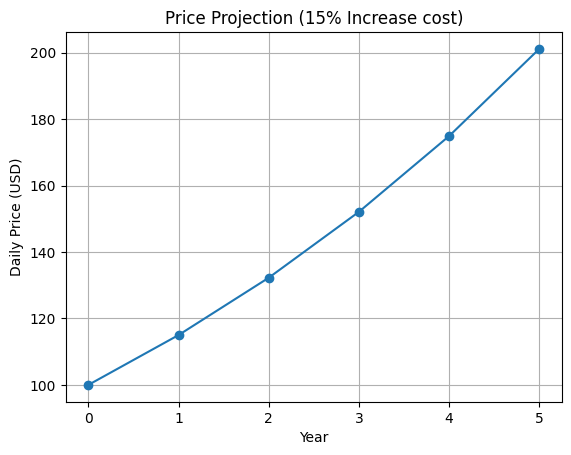

In [5]:
import matplotlib.pyplot as plt

years = [0, 1, 2, 3, 4, 5]
prices = [100, 115.0, 132.25, 152.09, 174.90, 201.14]

plt.plot(years, prices, marker="o")
plt.title("Price Projection (15% Increase cost)")
plt.xlabel("Year")
plt.ylabel("Daily Price (USD)")
plt.grid(True)
plt.show()


In [6]:
import pandas as pd

# Read CSV file
df = pd.read_csv("/home/fa064034/Downloads/costs-data.csv")

# Ensure Date column is datetime
df['Date'] = pd.to_datetime(df['Date'])

# Group by month and sum Total costs
monthly = df.groupby(df['Date'].dt.to_period("M"))['Total costs($)'].sum().reset_index()
monthly['Date'] = monthly['Date'].dt.to_timestamp()

# Calculate MoM growth rate
monthly['GrowthRate_%'] = monthly['Total costs($)'].pct_change() * 100

print(monthly)


         Date  Total costs($)  GrowthRate_%
0  2024-09-01         2904.93           NaN
1  2024-10-01         3053.33      5.108557
2  2024-11-01         3358.27      9.987129
3  2024-12-01         2940.60    -12.437058
4  2025-01-01         3187.21      8.386384
5  2025-02-01         3080.86     -3.336774
6  2025-03-01         3088.32      0.242140
7  2025-04-01         3173.59      2.761048
8  2025-05-01         3398.81      7.096695
9  2025-06-01         2542.76    -25.186757
10 2025-07-01         2503.89     -1.528654
11 2025-08-01          549.96    -78.035776
